# Where may I fly: UAS geographical zones from ANS CR data

[![Open in Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/eu_rules_en.ipynb)

**OpenSkyLab · notebook for the visual** [Where and how may I fly](https://openskylab.space/edu_viz_eu_rules.html) · [česká verze](eu_rules_cs.ipynb)

The visual walks through the decision tree of the European drone rules. Here you go through one of its branches, UAS geographical zones, on real data: you download the current zones published by Air Navigation Services of the Czech Republic (ŘLP), find out which zones the planned flight sites fall into, how high you may fly near airports and how zones change over time. This is a teaching aid, not legal advice: before a flight always check the zones in the DroneMap app and the conditions in the CAA measures of general nature (OOP).

**Goal:** load the list of geographical zones and their GeoJSON files, determine the zones for given sites and for a whole mapping flight area, convert the vertical limits of zones (AGL, AMSL, FL) to metres above ground, read height restrictions from the grid around airports, and compare the current and the next release of the zones.

**Data:** UAS geographical zones as GeoJSON (reference boundaries) from the ŘLP page https://aim.rlp.cz/?lang=cz&p=uas-gz, downloaded at run time; terrain elevation from the Digital terrain model of the Czech Republic, 5th generation (DMR 5G, ČÚZK).

**Tasks:** five. Write your answers in the *Your answer* cells below the tasks. Lines marked `# ◀ parameter` are meant to be changed; run the cell again with Shift + Enter.

**Time:** about 45 min. You need a Google account (Colab); nothing is installed on your computer. Run the cells in order from top to bottom.

## 1. Setup and the list of zones

In [1]:
%pip install -q shapely pyproj rasterio

Note: you may need to restart the kernel to use updated packages.


In [2]:
import re, html, json, time, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from shapely.geometry import shape, Point, box
import shapely
from pyproj import Transformer
import rasterio

AIM = "https://aim.rlp.cz"
def get(url, tries=4, **kw):
    for i in range(tries):
        try:
            r = requests.get(url, timeout=180, **kw); r.raise_for_status(); return r
        except requests.RequestException as e:
            print(url.split("/")[-1], type(e).__name__, "– retrying"); time.sleep(5 * (i + 1))
    raise RuntimeError(f"Could not download {url}")

page = get(f"{AIM}/?lang=en&p=uas-gz").content.decode("utf-8")
rows = []
for tr in re.findall(r"<tr.*?</tr>", page, re.S):
    href = re.search(r'href="(/data/uas/[^"]+\.json)"', tr)
    cols = [re.sub(r"\s+", " ", html.unescape(re.sub(r"<[^>]+>", " ", c))).strip() for c in re.findall(r"<td[^>]*>(.*?)</td>", tr, re.S)]
    if href and len(cols) >= 4:
        url = AIM + href.group(1)
        rows.append({"zone": cols[0], "description": cols[1], "file": cols[2], "size": cols[3],
                     "release": "current" if "/actual/" in url else url.split("/")[-2], "url": url})
zones = pd.DataFrame(rows)
mb = zones["size"].str.replace(",", ".").str.extract(r"([\d.]+)\s*(kB|MB)")
zones["MB"] = mb[0].astype(float) * np.where(mb[1] == "kB", 1e-3, 1)
pd.set_option("display.max_colwidth", 70)
zones[zones.release == "current"][["zone", "description", "MB"]]

,zone,description,MB
0,LKR311A - Railway Inner Zone – Railway Administration,Area less than 5 m from the centre line of the outer track,87.98000
1,LKR311B - Railway Outer Zone – Railway Administration,Area from 5 m to 60 m from the centre line of the outer track,171.67000
2,LKR311C - Railway Inner Zone – Other Operators,Area less than 5 m from the centre line of the outer track,1.54000
3,LKR311D - Railway Outer Zone – Other Operators,Area from 5 m to 60 m from the centre line of the outer track,2.99000
4,LKR312A - Protective zone of electrical substations 110kV+,Protection Zone of Electrical Substations above 110 kV+,1.11000
5,LKR312B - VHV lines protection zone 220kV+,Protection Area of High-Voltage Power Lines (HV),1.53000
6,LKR313 - Potable Water Reservoirs,Area of Water Surface at Maximum Backwater Level (Protection Zone I),0.77510
7,LKR314A - CTR and ATZ IFR Outer Zone,Restricted Area from CTR/ATZ IFR Boundary up to Inner Zone Boundary,0.01268
8,LKR314B - CTR and ATZ IFR Inner Zone,Restricted Area <1 km from Airport Perimeter and <1 km from RWY CT...,0.05816
9,LKR314C - CTR LKPR Outer Zone,Restricted Area from CTR LKPR Boundary up to Inner Zone Boundary.,0.00245


## 2. Which zones do the flight sites fall into?

We download zones up to a chosen file size (the largest layers, e.g. densely populated areas or class III roads, have hundreds of MB and would take long to download in Colab). For each site we find out which zones it lies in and what the vertical limit of the zone is.

In [3]:
MAX_MB = 20                   # ◀ parameter: largest file to download (MB)
SITES = {                     # ◀ parameter: flight sites (latitude, longitude)
    "Suchdol, campus":        (50.130, 14.373),
    "Roztoky forest":         (50.158, 14.385),
    "Kněževes by the airport": (50.124, 14.262),
    "Letňany":                (50.131, 14.522),
    "Pec pod Sněžkou":        (50.692, 15.733),
    "Luční bouda, Krkonoše":  (50.735, 15.697),
}
current = zones[(zones.release == "current") & (zones.MB <= MAX_MB) & ~zones.file.str.startswith("GRID")]
layers = {}
for _, z in current.iterrows():
    gj = get(z.url).json()
    layers[z.file.replace(".json", "")] = [(shape(f["geometry"]), f.get("properties") or {}) for f in gj["features"] if f.get("geometry")]
print(f"downloaded {len(layers)} layers, {sum(len(v) for v in layers.values())} polygons; not downloaded (large): {', '.join(zones[(zones.release == 'current') & (zones.MB > MAX_MB)].file)}")
hits = []
for site, (lat, lon) in SITES.items():
    pt = Point(lon, lat)
    for code, feats in layers.items():
        for geom, prop in feats:
            if geom.contains(pt):
                hits.append({"site": site, "layer": code, "zone": prop.get("ident"), "vertical limits": prop.get("vertical_limit"),
                             "description": current.set_index(current.file.str.replace(".json", "")).loc[code, "description"]})
hits = pd.DataFrame(hits)
hits if len(hits) else print("no site lies in a downloaded zone")

downloaded 22 layers, 6904 polygons; not downloaded (large): LKR311A.json, LKR311B.json, LKR316.json, LKR317C.json, LKR317D.json, LKR318C.json, GRID_ATZ.json, ed_318_a1_a2_all.json


,site,layer,zone,vertical limits,description
0,"Suchdol, campus",LKR314C,4LKR314C,GND - 3500 ft AMSL,Restricted Area from CTR LKPR Boundary up to Inner Zone Boundary.
1,"Suchdol, campus",LKR320A,LKPR2,3500 ft AMSL - FL95,"Airspaces Established under §44 of the Civil Aviation Act, Classif..."
2,"Suchdol, campus",LKR320A,LKPR9,FL95 - FL165,"Airspaces Established under §44 of the Civil Aviation Act, Classif..."
3,Roztoky forest,LKR314C,4LKR314C,GND - 3500 ft AMSL,Restricted Area from CTR LKPR Boundary up to Inner Zone Boundary.
4,Roztoky forest,LKR320A,LKPR2,3500 ft AMSL - FL95,"Airspaces Established under §44 of the Civil Aviation Act, Classif..."
5,Roztoky forest,LKR320A,LKPR9,FL95 - FL165,"Airspaces Established under §44 of the Civil Aviation Act, Classif..."
6,Kněževes by the airport,LKR314C,4LKR314C,GND - 3500 ft AMSL,Restricted Area from CTR LKPR Boundary up to Inner Zone Boundary.
7,Kněževes by the airport,LKR314D,5LKR314D,GND - 3500 ft AMSL,Circle with Radius 5.5 km from ARP
8,Kněževes by the airport,LKR320A,LKPR2,3500 ft AMSL - FL95,"Airspaces Established under §44 of the Civil Aviation Act, Classif..."
9,Kněževes by the airport,LKR320A,LKPR9,FL95 - FL165,"Airspaces Established under §44 of the Civil Aviation Act, Classif..."


> **✏️ Task 1.** Which zones do the individual sites lie in? Which site is free of restrictions from the downloaded layers, and why does that still not mean you may fly there (which large layers did you not download, and what could they change)? Add a site where you want to fly yourself to SITES and compare the result with the DroneMap map.

*Your answer:* 

## 3. Vertical limits of zones

A zone applies only between its lower and upper limit. Limits are given above ground (AGL), above mean sea level (AMSL) or as a flight level (FL, hundreds of feet at the standard pressure of 1013.25 hPa; here we treat it as an AMSL height for simplicity). 1 ft = 0.3048 m. Terrain elevation comes from the DMR 5G digital terrain model (ČÚZK).

In [4]:
def cuzk_raster(service, x0, y0, x1, y1, res=2.0):
    """Window of a ČÚZK raster (dmr5g, dmp1g, dmp_obrazova_korelace) in S-JTSK (EPSG:5514), heights in Bpv.
    Returns the height array (row 0 = north) and its transform."""
    nx, ny = int(round((x1 - x0) / res)), int(round((y1 - y0) / res))
    url = f"https://ags.cuzk.cz/arcgis2/rest/services/{service}/ImageServer/exportImage"
    params = {"bbox": f"{x0},{y0},{x1},{y1}", "bboxSR": 5514, "imageSR": 5514, "size": f"{nx},{ny}",
              "format": "tiff", "pixelType": "F32", "interpolation": "RSP_BilinearInterpolation", "f": "image"}
    for attempt in range(4):
        r = requests.get(url, params=params, timeout=120)
        if r.ok and r.headers.get("content-type", "").startswith("image"):
            break
        time.sleep(3 * (attempt + 1))
    r.raise_for_status()
    with rasterio.MemoryFile(r.content) as mem, mem.open() as ds:
        return ds.read(1).astype(float), ds.transform

FLIGHT_AGL = 120              # ◀ parameter: planned flight height above ground (m)
def level(txt, ground):
    """Convert one limit (e.g. 'GND', '3500 ft AMSL', '120 m AGL', 'FL95') to metres above ground."""
    s = txt.strip().upper().replace(" ", "")
    if s in ("GND", "SFC"): return 0.0
    if s.startswith("FL"): return float(s[2:]) * 100 * 0.3048 - ground
    m = re.match(r"([\d.]+)(FT|M)(AGL|AMSL|MSL)", s)
    v = float(m.group(1)) * (0.3048 if m.group(2) == "FT" else 1)
    return v if m.group(3) == "AGL" else v - ground

T_JTSK = Transformer.from_crs(4326, 5514, always_xy=True)
def terrain(lat, lon):
    """Terrain elevation (m a.s.l.) from DMR 5G at a point: the centre of a small 20 × 20 m window."""
    x, y = T_JTSK.transform(lon, lat)
    z, _ = cuzk_raster("dmr5g", x - 10, y - 10, x + 10, y + 10, res=2.0)
    return float(z[z.shape[0] // 2, z.shape[1] // 2])
ground = {site: terrain(lat, lon) for site, (lat, lon) in SITES.items()}
if len(hits):
    lim = hits["vertical limits"].str.split("-", n=1, expand=True)
    hits["terrain (m AMSL)"] = hits["site"].map(ground)
    hits["lower (m AGL)"] = [level(a, g) for a, g in zip(lim[0], hits["terrain (m AMSL)"])]
    hits["upper (m AGL)"] = [level(b, g) for b, g in zip(lim[1], hits["terrain (m AMSL)"])]
    hits[f"flight at {FLIGHT_AGL} m is in the zone"] = (hits["lower (m AGL)"] <= FLIGHT_AGL) & (FLIGHT_AGL <= hits["upper (m AGL)"])
    print(hits[["site", "zone", "vertical limits", "terrain (m AMSL)", "lower (m AGL)", "upper (m AGL)", f"flight at {FLIGHT_AGL} m is in the zone"]].round(0).to_string())
airspace = pd.DataFrame([{"area": p.get("ident"), "vertical limits": p.get("vertical_limit")} for _, p in layers.get("LKR320A", [])])
print("\nAirspace areas LKR320A by vertical limits:"); print(airspace["vertical limits"].value_counts().head(10).to_string())

                       site        zone              vertical limits  terrain (m AMSL)  lower (m AGL)  upper (m AGL)  flight at 120 m is in the zone
0           Suchdol, campus    4LKR314C           GND - 3500 ft AMSL             281.0            0.0          786.0                            True
1           Suchdol, campus       LKPR2          3500 ft AMSL - FL95             281.0          786.0         2615.0                           False
2           Suchdol, campus       LKPR9                 FL95 - FL165             281.0         2615.0         4749.0                           False
3            Roztoky forest    4LKR314C           GND - 3500 ft AMSL             255.0            0.0          811.0                            True
4            Roztoky forest       LKPR2          3500 ft AMSL - FL95             255.0          811.0         2640.0                           False
5            Roztoky forest       LKPR9                 FL95 - FL165             255.0         2640.0     

> **✏️ Task 2.** Both the outer and the inner zone of the Prague CTR (LKR314C and LKR314D) have an upper limit of 3500 ft AMSL: how many metres above ground is that in Suchdol? Why do some LKR320A airspace areas not concern a drone at 120 m at all? Why does terrain elevation matter for limits in AMSL or FL, and what does that mean for a flight in the mountains (Pec pod Sněžkou)?

*Your answer:* 

## 4. The grid around controlled airports

Around controlled airports (CTR) ŘLP publishes a grid of 30″ × 30″ cells (about 600 × 900 m) where each cell states up to what height above ground flight is allowed without further approval. The conditions of using the grid are in the relevant OOP.

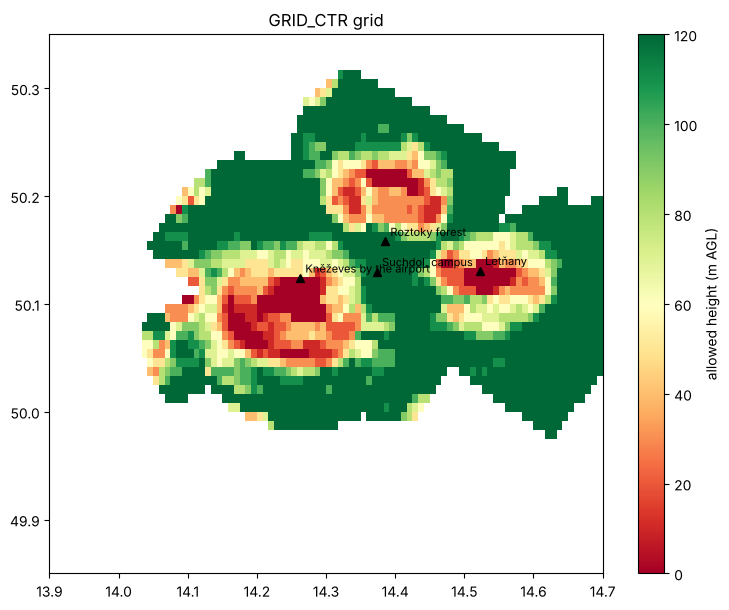

Suchdol, campus: up to 120 m above ground
Roztoky forest: up to 120 m above ground
Kněževes by the airport: up to 0 m above ground
Letňany: up to 0 m above ground


Pec pod Sněžkou: outside the grid
Luční bouda, Krkonoše: outside the grid


In [5]:
CENTER = (50.10, 14.30)       # ◀ parameter: centre of the map (latitude, longitude)
SPAN = 0.25                   # ◀ parameter: half the extent of the map (°)
grid_url = zones[(zones.release == "current") & (zones.file == "GRID_CTR.json")].url.iloc[0]
grid = [(shape(f["geometry"]), f["properties"]["vertical_limit"]) for f in get(grid_url).json()["features"]]
hmax = lambda txt: float(re.search(r"-\s*([\d.]+)\s*m\s*AGL", txt).group(1))
fig, ax = plt.subplots(figsize=(9, 7))
view = box(CENTER[1] - SPAN * 1.6, CENTER[0] - SPAN, CENTER[1] + SPAN * 1.6, CENTER[0] + SPAN)
cmap = plt.get_cmap("RdYlGn")
for g, v in grid:
    if g.intersects(view):
        x, y = g.exterior.xy; ax.fill(x, y, color=cmap(hmax(v) / 120), lw=0)
for site, (lat, lon) in SITES.items():
    ax.plot(lon, lat, "k^"); ax.annotate(site, (lon, lat), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set_xlim(view.bounds[0], view.bounds[2]); ax.set_ylim(view.bounds[1], view.bounds[3]); ax.set_aspect(1 / np.cos(np.radians(CENTER[0])))
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, 120)); plt.colorbar(sm, ax=ax, label="allowed height (m AGL)")
ax.set_title("GRID_CTR grid"); plt.show()
for site, (lat, lon) in SITES.items():
    v = [hmax(lim) for g, lim in grid if g.contains(Point(lon, lat))]
    print(f"{site}: {'outside the grid' if not v else f'up to {v[0]:.0f} m above ground'}")

> **✏️ Task 3.** Up to what height may you fly in Suchdol and in Kněževes according to the grid? How does the allowed height change towards the runway, and why? Move the map to another controlled airport (e.g. Brno 49.15° N, 16.69° E) and compare the shape of the grid. Why is a grid better than one large zone with a single height?

*Your answer:* 

## 5. The whole area of a mapping flight

A mapping flight covers an area, not a point. We compute what share of a square around the site lies in each zone (in metres, in UTM 33N coordinates).

In [6]:
SITE = "Roztoky forest"       # ◀ parameter: a site from SITES
HALF_M = 1500                 # ◀ parameter: half the side of the flight square (m)
T_UTM = Transformer.from_crs(4326, 32633, always_xy=True)
to_utm = lambda g: shapely.transform(g, lambda xy: np.column_stack(T_UTM.transform(xy[:, 0], xy[:, 1])))
lat, lon = SITES[SITE]; cx, cy = T_UTM.transform(lon, lat)
area = box(cx - HALF_M, cy - HALF_M, cx + HALF_M, cy + HALF_M)
share = []
for code, feats in layers.items():
    for geom, prop in feats:
        g = to_utm(geom)
        if g.intersects(area):
            share.append({"layer": code, "zone": prop.get("ident"), "vertical limits": prop.get("vertical_limit"), "share of area (%)": 100 * g.intersection(area).area / area.area})
for g, v in grid:
    gu = to_utm(g)
    if gu.intersects(area):
        share.append({"layer": "GRID_CTR", "zone": v, "vertical limits": v, "share of area (%)": 100 * gu.intersection(area).area / area.area})
share = pd.DataFrame(share)
print(f"{SITE}: square {2 * HALF_M / 1000:.1f} × {2 * HALF_M / 1000:.1f} km")
share.groupby(["layer", "vertical limits"])["share of area (%)"].sum().round(1).to_frame() if len(share) else print("the area does not lie in any downloaded zone")

Roztoky forest: square 3.0 × 3.0 km


share of area (%)
layer    vertical limits                       
GRID_CTR GND - 100 m AGL                    3.6
         GND - 110 m AGL                    7.9
         GND - 120 m AGL                   78.9
         GND - 60 m AGL                     3.6
         GND - 80 m AGL                     2.5
         GND - 90 m AGL                     3.5
LKR312A  GND - FL660                        0.1
LKR314C   GND - 3500 ft AMSL              100.0
LKR318B  GND-FL660                         16.4
LKR320A  3500 ft AMSL - FL95              100.0
         FL95 - FL165                     100.0
         GND - 2000 ft AMSL                 5.8

> **✏️ Task 4.** Which zones reach into the flight square even though the centre itself is not in them? How does the result change for a 0.5 km and a 3 km square? How would you split the mapping flight so that as much area as possible lies outside restrictions, and what would you have to arrange for the rest?

*Your answer:* 

## 6. Zones change

Besides the current zones, ŘLP also publishes releases that will take effect in the future (following the AIRAC cycle). We compare layers that exist in both releases: the number of zones, their identifiers and the area added or removed.

In [7]:
future = zones[(zones.release != "current") & (zones.MB <= MAX_MB)]
if future.empty:
    print("ŘLP is not publishing any future release of downloadable size right now.")
def load_layer(url):
    feats = [f for f in get(url).json()["features"] if f.get("geometry")]
    geoms = [shapely.make_valid(to_utm(shape(f["geometry"]))) for f in feats]
    return {f["properties"]["ident"] for f in feats}, shapely.union_all(geoms), len(feats)
for _, z in future.iterrows():
    ids0, u0, n0 = load_layer(zones[(zones.release == "current") & (zones.file == z.file)].url.iloc[0])
    ids1, u1, n1 = load_layer(z.url)
    added, removed = sorted(ids1 - ids0), sorted(ids0 - ids1)
    print(f"{z.file} (release {z.release}): zones {n0} → {n1}, area {u0.area / 1e6:.2f} → {u1.area / 1e6:.2f} km², "
          f"{u1.difference(u0).area / 1e6:.2f} km² added, {u0.difference(u1).area / 1e6:.2f} km² removed")
    for name, lst in [("new identifiers", added), ("withdrawn identifiers", removed)]:
        if lst: print(f"   {name}: {', '.join(lst[:12])}{' …' if len(lst) > 12 else ''}")

ŘLP is not publishing any future release of downloadable size right now.


> **✏️ Task 5.** Which layers change in the next release, and how many zones and how much area are added or removed? Why must a drone have current data for its geo-awareness function, and why is it not enough to check the zones once when planning a project that lasts several weeks?

*Your answer:* 

> **✏️ Extension (optional).** Classmates may have the notebook for the Brno area or for Hluboká nad Vltavou. Compare which zones and which allowed heights from the grid the flight sites near the airport and outside towns have, and how the grid around a controlled and an uncontrolled airport differ.

*Your answer:* 

---
### Data sources and references

- UAS geographical zones: Air Navigation Services of the Czech Republic (ŘLP ČR), AIM, https://aim.rlp.cz/?lang=en&p=uas-gz; zone map: https://dronemap.gov.cz
- Commission Implementing Regulation (EU) 2019/947 on the rules and procedures for the operation of unmanned aircraft, Article 15 (UAS geographical zones); Delegated Regulation (EU) 2019/945.
- Civil Aviation Authority of the Czech Republic: measures of general nature on UAS geographical zones (LKR311 to LKR320), https://www.caa.gov.cz
- Terrain elevation: Digital terrain model of the Czech Republic, 5th generation (DMR 5G), © ČÚZK, licence CC BY 4.0, service https://ags.cuzk.cz/arcgis2/rest/services/dmr5g/ImageServer

### How to cite

OpenSkyLab (2026). Where may I fly: UAS geographical zones from ANS CR data [notebook, teaching resource], version 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/eu_rules_en.ipynb. Licence CC BY 4.0.

Notebook text and code: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data are under their providers' licences (see above).

*This resource was developed by the OpenSkyLab team with the assistance of the generative AI Claude (Anthropic), used for drafting code and text. The authors are responsible for the content.*